# TabICLv2 Secondary Exploratory Test Evaluation

**Secondary Exploratory Evaluation on a Previously Evaluated Test Cohort**

This notebook renders the aggregate-only one-time evaluation report. It does not load participant data, predictions, labelled contexts, or model artifacts, and it does not perform inference. The results are not fresh independent validation, external validation, confirmatory evidence, or clinical diagnostic accuracy. Targets are questionnaire-defined developmental follow-up concerns.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
report_path = root / 'reports/generated/secondary-tabiclv2-test-evaluation-report.json'
report = json.loads(report_path.read_text(encoding='utf-8'))
assert report['status'] == 'completed_secondary_exploratory_tabiclv2_evaluation'
assert report['scope'] == 'secondary_exploratory_evaluation_on_previously_evaluated_test_cohort'
assert report['test_participants'] == 125
assert report['cohort_previously_evaluated'] is True
assert report['fresh_independent_validation'] is False
assert report['models_refit_or_adjusted_on_test'] is False
assert report['calibrators_adjusted_on_test'] is False
assert report['thresholds_adjusted_on_test'] is False
assert report['hybrids_evaluated'] is False
pd.Series({'status': report['status'], 'participants': report['test_participants'], 'runtime_seconds': report['runtime_seconds']})

status             completed_secondary_exploratory_tabiclv2_evalu...
participants                                                     125
runtime_seconds                                           112.757009
dtype: object

## Frozen-model comparison

In [2]:
labels = {'target_communication_concern': 'Communication', 'target_cognitive_concern': 'Cognitive', 'target_social_emotional_concern': 'Social-emotional'}
rows = []
for target, domain in report['domains'].items():
    original = domain['original_selected']['metrics']
    tabicl = domain['tabiclv2']['metrics']
    rows.append({
        'Domain': labels[target],
        'Original model': domain['original_selected']['model_configuration_version'],
        'Positive / negative': f"{domain['actual_positive_count']} / {domain['actual_negative_count']}",
        'Original PR-AUC': original['average_precision_pr_auc'],
        'TabICLv2 PR-AUC': tabicl['average_precision_pr_auc'],
        'PR-AUC difference': tabicl['average_precision_pr_auc'] - original['average_precision_pr_auc'],
        'Original accuracy': original['accuracy'],
        'TabICLv2 accuracy': tabicl['accuracy'],
        'Accuracy difference': tabicl['accuracy'] - original['accuracy'],
        'Balanced accuracy difference': tabicl['balanced_accuracy'] - original['balanced_accuracy'],
        'Sensitivity difference': tabicl['sensitivity'] - original['sensitivity'],
        'Specificity difference': tabicl['specificity'] - original['specificity'],
    })
comparison = pd.DataFrame(rows).set_index('Domain')
comparison.round(4)

,Original model,Positive / negative,Original PR-AUC,TabICLv2 PR-AUC,PR-AUC difference,Original accuracy,TabICLv2 accuracy,Accuracy difference,Balanced accuracy difference,Sensitivity difference,Specificity difference
Domain,,,,,,,,,,,
Communication,xgboost-regularized-balanced-v1,15 / 110,0.7414,0.7791,0.0377,0.744,0.888,0.144,-0.0045,-0.2000,0.1909
Cognitive,logistic-l2-balanced-v1,14 / 111,0.7345,0.7806,0.0461,0.768,0.832,0.064,0.0048,-0.0714,0.0811
Social-emotional,xgboost-regularized-balanced-v1,15 / 110,0.4892,0.5202,0.0310,0.776,0.816,0.040,0.0227,0.0000,0.0455


## Complete TabICLv2 test metrics

In [3]:
metric_rows = []
for target, domain in report['domains'].items():
    m = domain['tabiclv2']['metrics']
    metric_rows.append({'Domain': labels[target], 'PR-AUC': m['average_precision_pr_auc'], 'AUROC': m['roc_auc'], 'Accuracy': m['accuracy'], 'Balanced accuracy': m['balanced_accuracy'], 'Sensitivity': m['sensitivity'], 'Specificity': m['specificity'], 'PPV': m['precision'], 'NPV': m['negative_predictive_value'], 'F1': m['f1'], 'Brier score': m['brier_score']})
pd.DataFrame(metric_rows).set_index('Domain').round(4)

,PR-AUC,AUROC,Accuracy,Balanced accuracy,Sensitivity,Specificity,PPV,NPV,F1,Brier score
Domain,,,,,,,,,,
Communication,0.7791,0.9515,0.888,0.8212,0.7333,0.9091,0.5238,0.9615,0.6111,0.0542
Cognitive,0.7806,0.9093,0.832,0.8118,0.7857,0.8378,0.3793,0.9688,0.5116,0.0511
Social-emotional,0.5202,0.8673,0.816,0.7803,0.7333,0.8273,0.3667,0.9579,0.4889,0.0807


## Confusion matrices

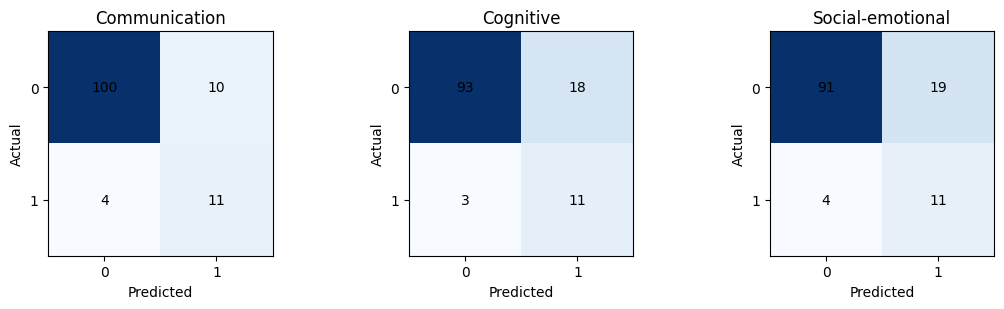

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for axis, (target, domain) in zip(axes, report['domains'].items()):
    cm = domain['tabiclv2']['metrics']['confusion_matrix']
    matrix = [[cm['true_negative'], cm['false_positive']], [cm['false_negative'], cm['true_positive']]]
    axis.imshow(matrix, cmap='Blues')
    for i in range(2):
        for j in range(2): axis.text(j, i, matrix[i][j], ha='center', va='center')
    axis.set(title=labels[target], xlabel='Predicted', ylabel='Actual', xticks=[0, 1], yticks=[0, 1])
plt.tight_layout()
plt.show()

## Paired uncertainty for TabICLv2 minus original

In [5]:
interval_rows = []
for target, domain in report['domains'].items():
    intervals = domain['paired_uncertainty']['tabiclv2_minus_original_95_percentile_intervals']
    for metric in ['average_precision_pr_auc', 'accuracy', 'balanced_accuracy', 'sensitivity', 'specificity', 'brier_score']:
        interval_rows.append({'Domain': labels[target], 'Metric': metric, 'Lower 95%': intervals[metric]['lower'], 'Upper 95%': intervals[metric]['upper']})
pd.DataFrame(interval_rows).set_index(['Domain', 'Metric']).round(4)

Lower 95%  Upper 95%
Domain           Metric                                        
Communication    average_precision_pr_auc    -0.0324     0.1175
                 accuracy                     0.0798     0.2160
                 balanced_accuracy           -0.1152     0.0985
                 sensitivity                 -0.4000     0.0000
                 specificity                  0.1182     0.2727
                 brier_score                 -0.0118     0.0030
Cognitive        average_precision_pr_auc    -0.0610     0.1720
                 accuracy                     0.0160     0.1200
                 balanced_accuracy           -0.0756     0.0631
                 sensitivity                 -0.2143     0.0000
                 specificity                  0.0270     0.1441
                 brier_score                 -0.0176     0.0079
Social-emotional average_precision_pr_auc    -0.0354     0.1110
                 accuracy                     0.0000     0.0880
                 balanced_accuracy            0.0000     0.0500
                 sensitivity                  0.0000     0.0000
                 specificity                  0.0000     0.1000
                 brier_score                 -0.0117     0.0074

## Interpretation and limitations

TabICLv2 is compared numerically with the original frozen selected model on exactly the same 125 participants. Paired bootstrap intervals quantify descriptive participant-level uncertainty. Small positive counts, reuse of a previously evaluated cohort, inspection of multiple domains and metrics, and context-size differences from development cross-validation limit inference. A numerical improvement is not reliable evidence of superiority when its paired interval includes zero. No model, calibrator, threshold, or hybrid was selected or adjusted from these outcomes.